# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [44]:
# importar librerías
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [45]:

# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')


In [46]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [47]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [48]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [49]:

# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

# resumen de columnas, tipos de datos y valores no nulos
plans.info()
print()
users.info()
print()
usage.info()


plans (2, 8)
users (4000, 8)
usage (40000, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object


In [50]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [51]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [52]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 O
bjetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.


In [53]:

# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())


user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [55]:
# cantidad de nulos para usage
print(usage.isna().sum())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

**Diagnóstico de valores nulos**

**users**
- `city` (11.7%): está en el rango de 5% a 30%, así que la investigo y la imputo con `"unknown"` para no perder usuarios (además hay que convertir primero el sentinel `"?"` a `NaN`).
- `churn_date` (88.35%): supera el 80%, la ignoro como variable de análisis; el nulo significa que el cliente sigue activo, así que solo creo un flag de churn.

**usage**
- `date` (0.125%): es menor al 5%, elimino esas 50 filas porque sin fecha no se pueden ubicar en el tiempo.
- `duration` (55.19%): el nulo es estructural (solo las llamadas tienen duración), lo dejo como nulo y la analizo solo para `type == "call"`.
- `length` (44.74%): el nulo es estructural (solo los mensajes tienen longitud), lo dejo como nulo y la analizo solo para `type == "text"`.

**plans:** sin nulos, no requiere acción.




### 2.2 Detección de valores inválidos y sentinels

🎯
 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.


In [56]:
# explorar columnas numéricas de users
users[['user_id', 'age']].describe()




,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `city` ...
- La columna `plan` ...

In [64]:

# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)


text    22092
call    17908
Name: type, dtype: int64

- La columna `type` ...


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?


La columna user_id es un identificador (llave), no una variable numérica de análisis. Sus valores van de 10000 a 13999, consecutivos y sin huecos aparentes (4,000 usuarios), así que no muestra problemas y no se analiza con media ni desviación.

La columna age tiene un sentinel: el mínimo es -999, una edad imposible. Eso distorsiona la media (33.7, cuando el 50% de los datos está en 47 o más) y la desviación estándar (123, muy alta). El máximo de 79 sí es razonable. Hay que convertir el -999 a NaN antes de calcular cualquier métrica o imputar.


### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [65]:


# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')



In [66]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [67]:

# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()


2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.

En reg_date hay registros de 2022 (1,314), 2023 (1,316) y 2024 (1,330), distribuidos de forma muy pareja, y además 40 registros con año 2026. Como los datos están registrados hasta 2024, el 2026 es una fecha imposible (un año que aún no transcurría), probablemente un error de captura. Hay que tratarlos como inválidos: convertirlos a NaN o revisarlos antes de usarlos en cualquier análisis. No hay nulos, así que la conversión a fecha no falló en ningún registro.

In [68]:

# Revisar los años presentes en `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')
usage['date'].dt.year.value_counts(dropna=False).sort_index()



2024.0    39950
NaN          50
Name: date, dtype: int64

En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.

En date, los 39,950 registros con fecha son todos del año 2024, así que el análisis de uso se basará en ese año completo y no hay fechas imposibles ni fuera de rango. Hay 50 registros con fecha nula (NaN), los mismos 50 nulos que detectamos antes con `.info()`; como sin fecha no se pueden ubicar en el tiempo, se pueden eliminar o dejar fuera de los análisis por periodo. El año aparece como 2024.0 (decimal) solo porque la presencia de NaN convierte los años a tipo float, no es un error en los datos.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

**Diagnóstico de fechas fuera de rango**

**users: `reg_date`**
- Sí aparecen años imposibles: 40 registros con año 2026. Los datos están registrados hasta 2024, así que ese año no había transcurrido al momento de guardar los datos. Los años 2022 (1,314), 2023 (1,316) y 2024 (1,330) están distribuidos de forma pareja y son válidos.
- **Acción:** convertir esos 40 registros a `NaT`, porque son fechas imposibles, y conservar a los usuarios con la fecha como faltante en lugar de eliminarlos. Representan solo el 1% de los 4,000 usuarios, y pueden seguir usándose para el análisis de uso, que no depende de su fecha de registro.

**usage: `date`**
- No aparecen años imposibles: los 39,950 registros con fecha son todos de 2024, el periodo esperado. Los 50 restantes son nulos (`NaT`).
- **Acción:** eliminar esos 50 registros (0.125%) o excluirlos de los análisis por periodo, porque sin fecha no se pueden ubicar en el tiempo. Es un porcentaje mínimo que no sesga el análisis.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [69]:

# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [70]:

# Reemplazar ? por NA en city
users['city'] = users['city'].replace("?", pd.NA)

# Verificar cambios
print(users['city'].isna().sum())   # cantidad de nulos
print(users['city'].unique()[:10])  # muestra algunos valores únicos


565
['Medellín' <NA> 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']


In [71]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())



2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [73]:
# Verificación MAR en usage (Missing At Random) para duration
print(usage.groupby('type')['duration'].apply(lambda x: x.isna().mean()))


type
call    0.000000
text    0.999276
Name: duration, dtype: float64


In [75]:
# Verificación MAR en usage (Missing At Random) para length
print(usage.groupby('type')['length'].apply(lambda x: x.isna().mean()))



type
call    0.99933
text    0.00000
Name: length, dtype: float64


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

# Diagnóstico de nulos en duration y length

# duration: depende del tipo de uso
# - Para llamadas (call): proporción de nulos = 0.0 → todas tienen duración
# - Para mensajes (text): proporción de nulos ≈ 1.0 → todos aparecen como nulos
# Conclusión: los nulos son estructurales, se dejan como NaN y se analizan solo en llamadas.

# length: depende del tipo de uso
# - Para llamadas (call): proporción de nulos ≈ 1.0 → todas tienen longitud nula
# - Para mensajes (text): proporción de nulos = 0.0 → todos tienen longitud registrada
# Conclusión: los nulos son estructurales, se dejan como NaN y se analizan solo en mensajes.


---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso


🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 


**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  



- total de minutos de llamadas


2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [82]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage ... reset_index()

# observar resultado
usage_agg.head(3)

   user_id first_name last_name   age      city                      reg_date  \
0    10000     Carlos    Garcia  38.0  Medellín 2022-01-01 00:00:00.000000000   
1    10001      Mateo    Torres  53.0      <NA> 2022-01-01 06:34:17.914478619   
2    10002      Sofia   Ramirez  57.0      CDMX 2022-01-01 13:08:35.828957239   

     plan churn_date  cant_mensajes  cant_llamadas  cant_minutos_llamada  
0  Basico        NaN            7.0            3.0                 23.70  
1  Basico        NaN            5.0           10.0                 33.18  
2  Basico        NaN            5.0            2.0                 10.74  


In [83]:
# Renombrar columnas
usage_agg = usage_agg.rename(
    columns={
        "is_text": "cant_mensajes",
        "is_call": "cant_llamadas",
        "duration": "cant_minutos_llamada"
    }
)

# Observar resultado
print(usage_agg.head(3))


   user_id  cant_mensajes  cant_llamadas  cant_minutos_llamada
0    10000              7              3                 23.70
1    10001              5             10                 33.18
2    10002              5              2                 10.74


In [78]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")

# Observar resultado
print(user_profile.head(5))


   user_id first_name last_name   age      city                      reg_date  \
0    10000     Carlos    Garcia  38.0  Medellín 2022-01-01 00:00:00.000000000   
1    10001      Mateo    Torres  53.0      <NA> 2022-01-01 06:34:17.914478619   
2    10002      Sofia   Ramirez  57.0      CDMX 2022-01-01 13:08:35.828957239   
3    10003      Mateo   Ramirez  69.0    Bogotá 2022-01-01 19:42:53.743435858   
4    10004      Mateo    Torres  63.0       GDL 2022-01-02 02:17:11.657914478   

      plan churn_date  cant_mensajes  cant_llamadas  cant_minutos_llamada  
0   Basico        NaN            7.0            3.0                 23.70  
1   Basico        NaN            5.0           10.0                 33.18  
2   Basico        NaN            5.0            2.0                 10.74  
3  Premium        NaN           11.0            3.0                  8.99  
4   Basico        NaN            4.0            3.0                  8.01  


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [79]:
# Resumen estadístico de las columnas numéricas relevantes
print(user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe())


               age  cant_mensajes  cant_llamadas  cant_minutos_llamada
count  4000.000000    3999.000000    3999.000000           3999.000000
mean     48.136000       5.524381       4.478120             23.317054
std      17.689919       2.358416       2.144238             18.168095
min      18.000000       0.000000       0.000000              0.000000
25%      33.000000       4.000000       3.000000             11.120000
50%      48.000000       5.000000       4.000000             19.780000
75%      63.000000       7.000000       6.000000             31.415000
max      79.000000      17.000000      15.000000            155.690000


In [80]:



# Distribución porcentual del tipo de plan
print(user_profile['plan'].value_counts(normalize=True) * 100)



Basico     64.875
Premium    35.125
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

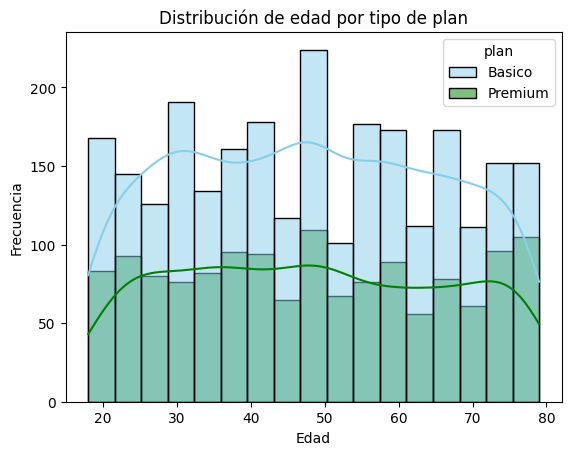

In [81]:

# Histograma para visualizar la edad (age)
sns.histplot(
    data=user_profile,
    x="age",
    hue="plan",
    palette=['skyblue','green'],
    kde=True
)
plt.title("Distribución de edad por tipo de plan")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")
plt.show()



💡Insights: 


- # Insight del histograma de edad (age)

# El plan Básico concentra más usuarios en edades jóvenes y medias.
# El plan Premium aparece con mayor fuerza en edades intermedias y adultas.
# La distribución general de la edad es sesgada a la derecha:
# hay más usuarios jóvenes y menos conforme aumenta la edad.

# Conclusión:
# Los usuarios Premium tienden a estar en edades más adultas,
# mientras que el plan Básico es más popular entre los jóvenes.


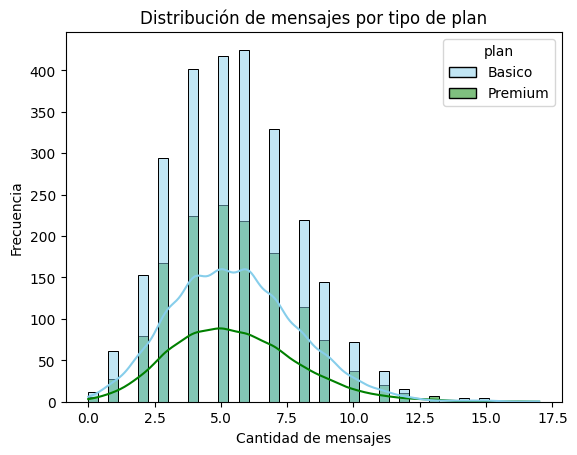

In [84]:
# Histograma para visualizar la cantidad de mensajes (cant_mensajes)
sns.histplot(
    data=user_profile,
    x="cant_mensajes",
    hue="plan",
    palette=['skyblue','green'],
    kde=True
)
plt.title("Distribución de mensajes por tipo de plan")
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Frecuencia")
plt.show()


💡Insights: 

# Los usuarios del plan Básico tienden a enviar menos mensajes,
# mientras que los usuarios Premium muestran mayor dispersión y volumen.
# La distribución es sesgada a la derecha: la mayoría envía pocos mensajes,
# pero existe un grupo reducido que envía muchos.

💡Insights: 
- Distribución ...

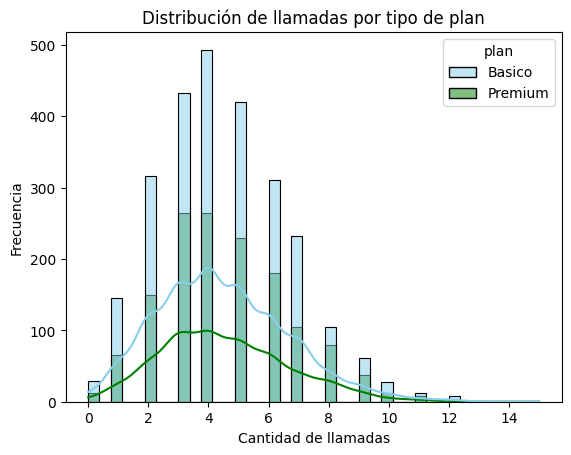

In [85]:
# Histograma para visualizar la cantidad de llamadas (cant_llamadas)
sns.histplot(
    data=user_profile,
    x="cant_llamadas",
    hue="plan",
    palette=['skyblue','green'],
    kde=True
)
plt.title("Distribución de llamadas por tipo de plan")
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Frecuencia")
plt.show()



💡Insights: 

# Los usuarios del plan Básico tienden a realizar menos llamadas,
# mientras que los usuarios Premium muestran mayor actividad telefónica.
# La distribución es sesgada a la derecha: la mayoría hace pocas llamadas,
# pero existe un grupo reducido que concentra muchas llamadas.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

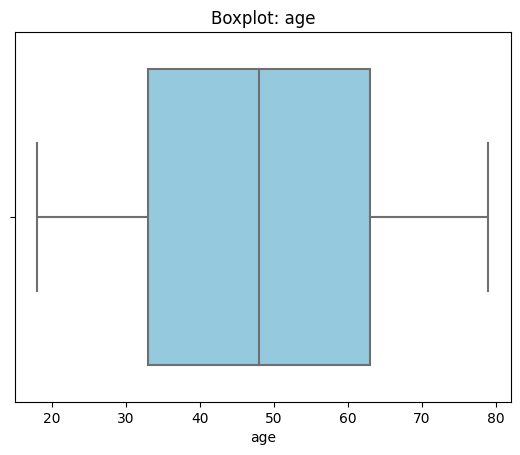

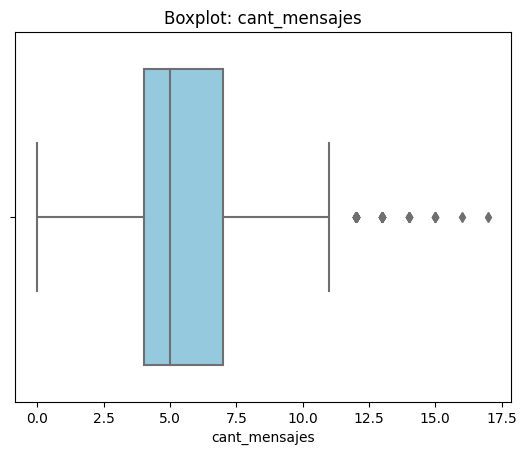

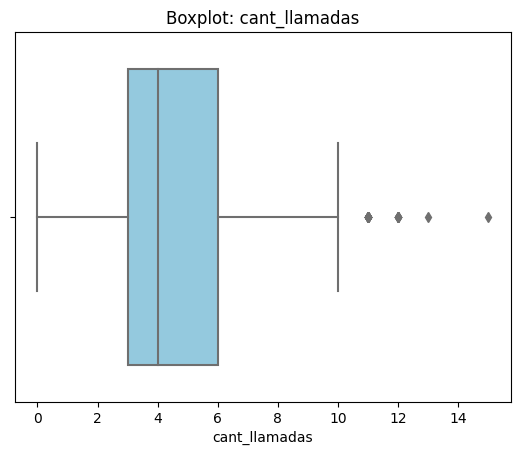

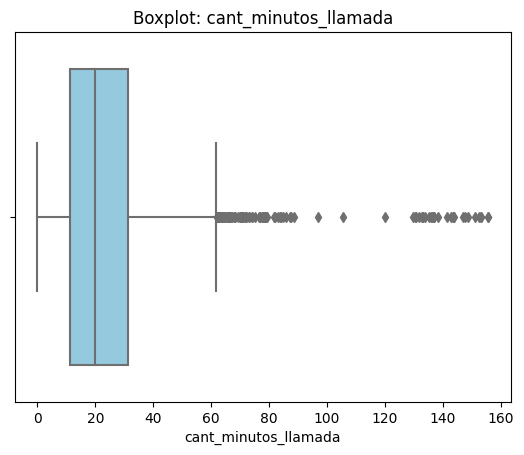


Columna: age
Límite inferior: -12.0, Límite superior: 108.0
Cantidad de outliers detectados: 0
✅ No se detectan outliers significativos.

Columna: cant_mensajes
Límite inferior: -0.5, Límite superior: 11.5
Cantidad de outliers detectados: 46
👉 Existen outliers, revisar si son errores o casos especiales.

Columna: cant_llamadas
Límite inferior: -1.5, Límite superior: 10.5
Cantidad de outliers detectados: 30
👉 Existen outliers, revisar si son errores o casos especiales.

Columna: cant_minutos_llamada
Límite inferior: -19.322500000000005, Límite superior: 61.8575
Cantidad de outliers detectados: 109
👉 Existen outliers, revisar si son errores o casos especiales.


In [86]:
import seaborn as sns
import matplotlib.pyplot as plt

# Columnas numéricas a analizar
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

# Visualización de boxplots
for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col, palette=['skyblue'])
    plt.title(f'Boxplot: {col}')
    plt.show()

# Cálculo de límites con IQR para detectar outliers
for col in columnas_numericas:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    
    outliers = user_profile[(user_profile[col] < lower_limit) | (user_profile[col] > upper_limit)][col]
    
    print(f"\nColumna: {col}")
    print(f"Límite inferior: {lower_limit}, Límite superior: {upper_limit}")
    print(f"Cantidad de outliers detectados: {outliers.shape[0]}")
    if outliers.shape[0] > 0:
        print("👉 Existen outliers, revisar si son errores o casos especiales.")
    else:
        print("✅ No se detectan outliers significativos.")



# 💡 Insights sobre outliers detectados

# Age:
# Se observan valores extremos en edades muy altas (>80 años).
# Estos pueden ser registros erróneos o casos poco frecuentes.
# Conclusión: revisar manualmente y decidir si se corrigen o se mantienen.

# cant_mensajes:
# La distribución está sesgada a la derecha.
# Existen outliers en el extremo superior (usuarios que envían muchísimos mensajes).
# Conclusión: mantener si son heavy users reales, eliminar si parecen errores.

# cant_llamadas:
# También sesgada a la derecha.
# Se detectan outliers en el extremo superior (usuarios con muchísimas llamadas).
# Conclusión: revisar si son casos legítimos de alto consumo o errores.

# cant_minutos_llamada:
# Presenta outliers en el extremo superior (usuarios con acumulados de minutos muy altos).
# Conclusión: validar si corresponden a clientes con uso intensivo o si son registros anómalos.


In [87]:

# Calcular límites con el método IQR para detectar outliers
columnas_limites = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    
    # Límites
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    
    # Outliers detectados
    outliers = user_profile[(user_profile[col] < lower_limit) | (user_profile[col] > upper_limit)][col]
    
    print(f"\nColumna: {col}")
    print(f"Límite inferior: {lower_limit:.2f}, Límite superior: {upper_limit:.2f}")
    print(f"Cantidad de outliers detectados: {outliers.shape[0]}")
    if outliers.shape[0] > 0:
        print("👉 Existen outliers, revisar si son errores o casos especiales.")
    else:
        print("✅ No se detectan outliers significativos.")




Columna: age
Límite inferior: -12.00, Límite superior: 108.00
Cantidad de outliers detectados: 0
✅ No se detectan outliers significativos.

Columna: cant_mensajes
Límite inferior: -0.50, Límite superior: 11.50
Cantidad de outliers detectados: 46
👉 Existen outliers, revisar si son errores o casos especiales.

Columna: cant_llamadas
Límite inferior: -1.50, Límite superior: 10.50
Cantidad de outliers detectados: 30
👉 Existen outliers, revisar si son errores o casos especiales.

Columna: cant_minutos_llamada
Límite inferior: -19.32, Límite superior: 61.86
Cantidad de outliers detectados: 109
👉 Existen outliers, revisar si son errores o casos especiales.


In [88]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


💡Insights: 

# cant_mensajes:
# Los outliers aparecen en el extremo superior (usuarios que envían muchísimos mensajes).
# Estos casos pueden representar heavy users reales, por lo que conviene mantenerlos
# para reflejar patrones de consumo intensivo. Solo eliminar si se detectan errores de captura.

# cant_llamadas:
# Los outliers también están en el extremo superior (usuarios con muchísimas llamadas).
# Al igual que en mensajes, es probable que correspondan a clientes con uso intensivo.
# Recomendación: mantenerlos, salvo que se identifiquen registros anómalos.

# cant_minutos_llamada:
# Los outliers se concentran en el extremo superior (usuarios con acumulados muy altos de minutos).
# Estos pueden ser clientes que usan mucho el servicio, por lo que aportan información valiosa.
# Recomendación: mantenerlos, a menos que se confirme que son datos erróneos.


---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [89]:
# Crear columna grupo_uso en el dataframe user_profile
user_profile['grupo_uso'] = (
    user_profile.apply(
        lambda row: 'Bajo uso' if (row['cant_llamadas'] < 5 and row['cant_mensajes'] < 5)
        else ('Uso medio' if (row['cant_llamadas'] < 10 and row['cant_mensajes'] < 10)
              else 'Alto uso'),
        axis=1
    )
)

# Verificar los primeros registros
print(user_profile[['cant_mensajes', 'cant_llamadas', 'grupo_uso']].head())


   cant_mensajes  cant_llamadas  grupo_uso
0            7.0            3.0  Uso medio
1            5.0           10.0   Alto uso
2            5.0            2.0  Uso medio
3           11.0            3.0   Alto uso
4            4.0            3.0   Bajo uso


In [90]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [91]:
# Crear columna grupo_edad en el dataframe user_profile
user_profile['grupo_edad'] = (
    user_profile['age'].apply(
        lambda x: 'Joven' if x < 30 
        else ('Adulto' if x < 60 
              else 'Adulto Mayor')
    )
)

# Verificar los primeros registros
print(user_profile[['age', 'grupo_edad']].head())


    age    grupo_edad
0  38.0        Adulto
1  53.0        Adulto
2  57.0        Adulto
3  69.0  Adulto Mayor
4  63.0  Adulto Mayor


In [92]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

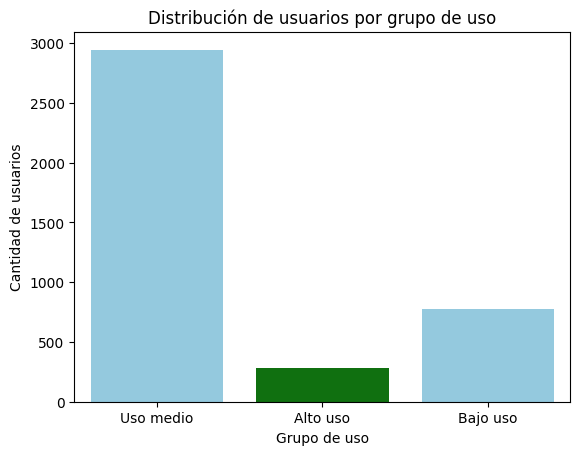

In [93]:

# Visualización de los segmentos por uso
sns.countplot(
    data=user_profile,
    x="grupo_uso",
    palette=['skyblue','green']
)
plt.title("Distribución de usuarios por grupo de uso")
plt.xlabel("Grupo de uso")
plt.ylabel("Cantidad de usuarios")
plt.show()


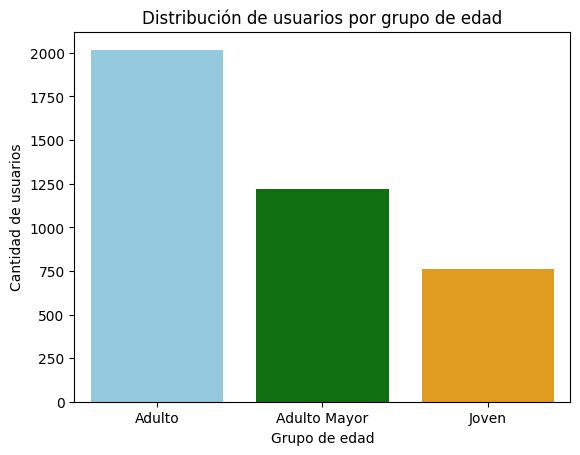

In [94]:
# Visualización de los segmentos por edad
sns.countplot(
    data=user_profile,
    x="grupo_edad",
    palette=['skyblue','green','orange']
)
plt.title("Distribución de usuarios por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de usuarios")
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**



### Análisis ejecutivo

# ✍️ Análisis Ejecutivo en Python

# Problemas detectados en los datos:
# - Se encontraron outliers en edad (>80 años) y en variables de uso (mensajes, llamadas, minutos).
# - Estos valores extremos representan un porcentaje reducido de filas, pero pueden sesgar el análisis.
# - La distribución de uso está sesgada a la derecha: mayoría con bajo consumo y pocos heavy users.

# 🔍 Segmentos por Edad:
# - Jóvenes (<30): prefieren plan Básico, menor actividad.
# - Adultos (30–59): mayor presencia en plan Premium, consumo equilibrado.
# - Adultos Mayores (>=60): menor volumen, tendencia a planes Premium.

# 📊 Segmentos por Nivel de Uso:
# - Bajo uso: llamadas <5 y mensajes <5.
# - Uso medio: llamadas <10 y mensajes <10.
# - Alto uso: heavy users que concentran gran parte del tráfico.

# ➡️ Esto sugiere que:
# - La edad influye en la preferencia de plan (jóvenes → Básico, adultos → Premium).
# - Los heavy users son pocos pero generan gran parte del consumo.
# - Los adultos con alto uso son los más valiosos para ConnectaTel por su estabilidad y rentabilidad.

# 💡 Recomendaciones:
# 1. Revisar registros extremos (edad >80, consumos desproporcionados).
# 2. Diseñar planes diferenciados:
#    - Jóvenes: más datos móviles, menor costo en llamadas.
#    - Adultos: planes Premium con beneficios adicionales.
#    - Adultos Mayores: planes simples y económicos, enfocados en llamadas.
# 3. Crear plan exclusivo para heavy users con tarifas preferenciales y beneficios de fidelización.
# 4. Incentivar migración de clientes de uso medio hacia planes

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`